In [1]:
# Import Python packages
import sys
import os
import subprocess
import matplotlib.pyplot as plt
import numpy as np
import scipy.constants as const

# Import the Simulation packages
project_directory = subprocess.check_output(['git', 'rev-parse', '--show-toplevel']).strip().decode('utf-8')
sys.path.append(project_directory + '/spinsimulation')  # Remove the square brackets
from SpinSys import SpinSys
import SpinHamiltonian as hamil 
import calcdIdV as dIdV
import calcdIdV3 as dIdV3
import calcESR as ESR
import SpinVisualization as vis
%load_ext autoreload
%autoreload 2

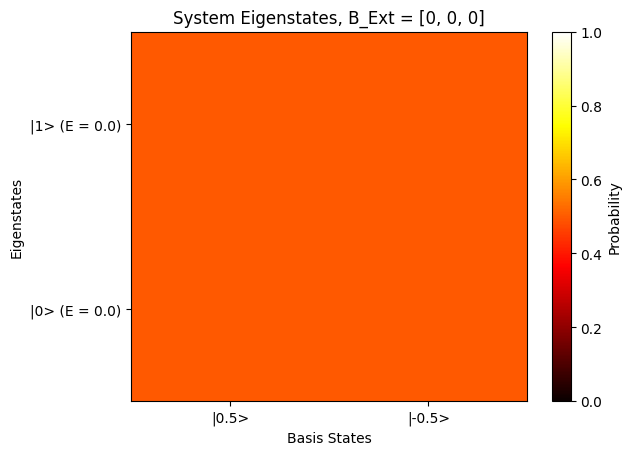

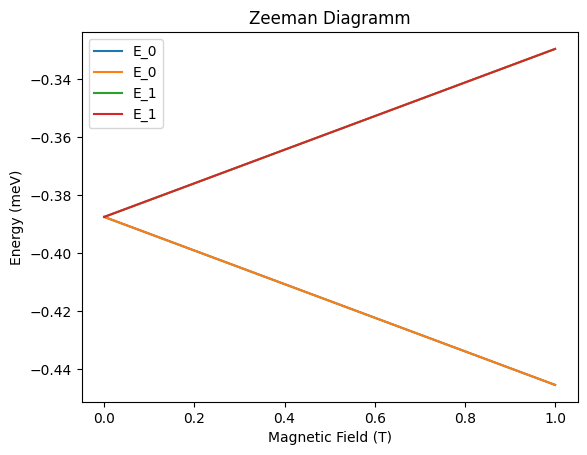

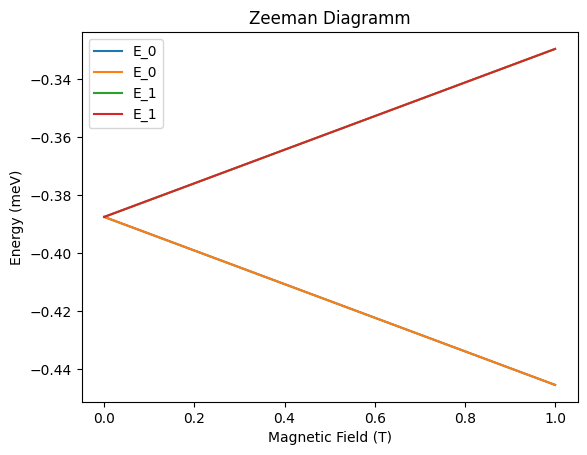

In [2]:
# Define the Spin System
spinsys=SpinSys([0.5])

spinsys.Dvector = [-1.55]
spinsys.Evector = [0.31]
# Add the Spin Hamiltonian parameters
spinsys.B=[0,0,00] #Add a magnetic field in Tesla
spinsys.BTip=[1e-7,0,0] # Add a tipfield for driving
spinsys.T=1 

vis.plotEigenMatrix(spinsys)
vis.plotZeemanDiagramm(spinsys)

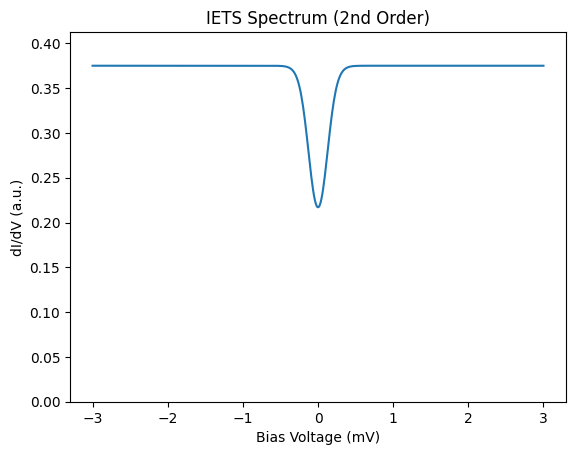

In [3]:
# dIdV Calculation
spinsys=SpinSys([0.5])
spinsys.T=0.5
spinsys.ReadoutSpin=0 # Set the readout spin
spinsys.TipPolarization=[0,0,0.0]
spinsys.B=[0,0,1] # Magnetic field in Tesla
hamil.calcEigEnergies(spinsys)
vis.plotIETS(spinsys, Vrange=[-3,3], N=500, norm=False, order='2nd')

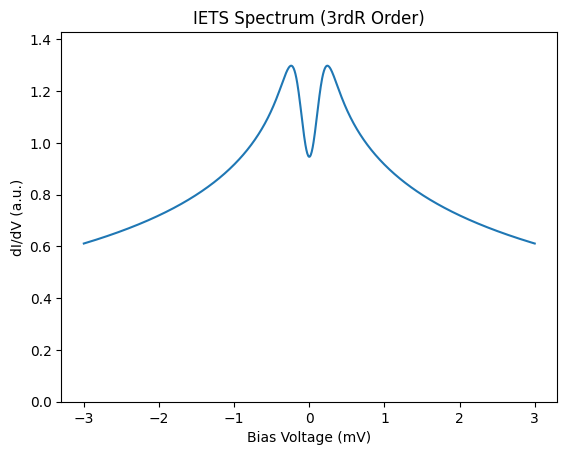

In [7]:
import calcdIdV3 as spec3

spinsys=SpinSys([0.5])
spinsys.J=[-0.4]  # Set the Kondo coupling strength
spinsys.U=[0]  # Set the Coulomb repulsion strength
spinsys.B=[0,0,1]
spinsys.BTip=[0,0,0] # Add a tipfield for driving
spinsys.T=0.5  # Set the temperature
hamil.calcEigEnergies(spinsys)
V_array = np.linspace(-3, 3, 1000)  # Define the voltage range for the IETS calculation
#spec3.spec3(spinsys, 0, V_array)

vis.plotIETS(spinsys, Vrange=[-3, 3], N=1000, norm=False, order='3rdR')

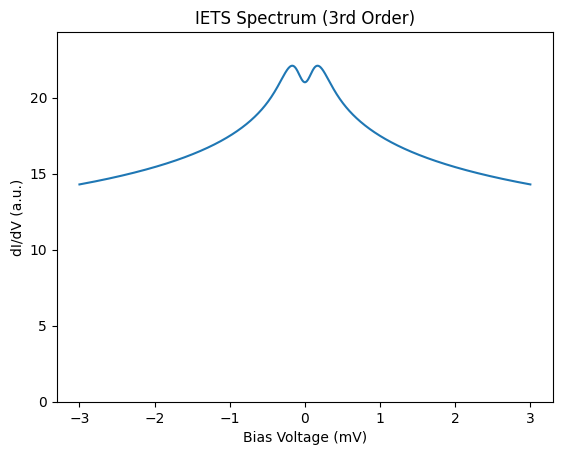

In [5]:
import calcBath as bath 
import calcdIdV3 as spec3

from SpinSys import SpinSys
import SpinHamiltonian as hamil 
import calcdIdV as dIdV
import calcdIdV3 as dIdV3
import calcESR as ESR
import SpinVisualization as vis

spinsys=SpinSys([3.5])
spinsys.J=[-0.2]  # Set the Kondo coupling strength

spinsys.T=0.5
spinsys.ReadoutSpin=0 # Set the readout spin
spinsys.TipPolarization=[0,0,0.0]
spinsys.B=[0,0,1] # Magnetic field in Tesla
hamil.calcEigEnergies(spinsys)
# [x, y, z, u] = spec3.e_transport(spinsys)
# print("Transport values:", x, y, z, u)

# y = tunnelingBroadenedStepFunction(x_V)
# y = fstep(x)
vis.plotIETS(spinsys, Vrange=[-3, 3], N=1000, norm=False, order='3rd')

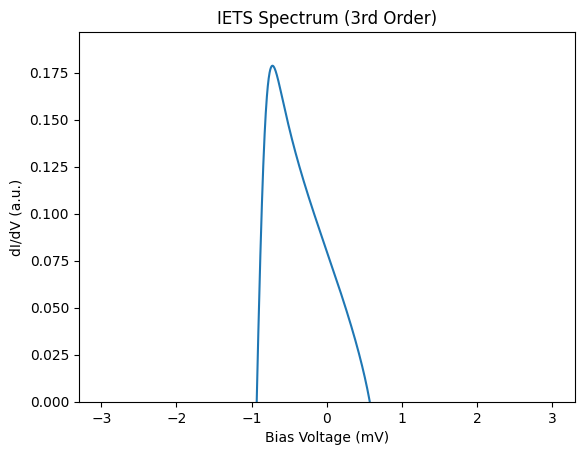

In [6]:
import calcBath as bath 
import calcdIdV3 as spec3
import numpy as np
from SpinSys import SpinSys
import SpinHamiltonian as hamil 
import calcdIdV as dIdV
import calcdIdV3 as dIdV3
import calcESR as ESR
import SpinVisualization as vis

spinsys=SpinSys([0.5,0.5])
spinsys.U=[0.2,0.2] 
spinsys.J=[0.4,0.5]  # Set the Kondo coupling strength
# Add the Spin Hamiltonian parameters
spinsys.B=[0,0,0.5] #Add a magnetic field in Tesla
spinsys.BTip=[1e-7,0,0] # Add a tipfield for driving
spinsys.T=1 
spinsys.Jvector=np.array([[1,1,1]]) # Exchange coupling in meV
spinsys.Dvector=np.array([1.9,0])  # Anisotropy of the Spin 1
spinsys.AtomPositions=np.array([[0,0,0],[2,1,0]]) # Positions of the atoms in lattice units
spinsys.DipoleBool=[False] # Dipole interaction is not included
spinsys.T=0.5
spinsys.ReadoutSpin=0 # Set the readout spin
spinsys.TipPolarization=[0,0,0.0]
spinsys.B=[0,0,1] # Magnetic field in Tesla
hamil.calcEigEnergies(spinsys)
# [x, y, z, u] = spec3.e_transport(spinsys)
# print("Transport values:", x, y, z, u)

# y = tunnelingBroadenedStepFunction(x_V)
# y = fstep(x)
vis.plotIETS(spinsys, Vrange=[-3, 3], N=2000, norm=False, order='3rd')